# 02 — Scorecard Development (Champion Model)

**Question for this notebook:** which application-time characteristics separate good from bad loans, and can they be combined into an interpretable, points-based scorecard?

Only the **development** sample (2012-Q4–2013) is used here, split 70/30 into train and validation. OOT (2014) and monitoring (2015) data are not touched.

In [ ]:
%load_ext autoreload
%autoreload 2

import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
from src import scorecard as sc
from src.data_prep import load_model_data, split_development
from src.features import CATEGORICAL, DERIVED_FEATURES, add_derived_features, candidate_features
from src.validation import gini, ks_statistic

pd.set_option("display.max_rows", 200)
TARGET = config.TARGET

data = add_derived_features(load_model_data())
train, valid = split_development(data)
features = candidate_features(data.columns.tolist())
print(f"{len(features)} candidate features")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
62 candidate features


In [2]:
pd.DataFrame({
    "loans": [len(train), len(valid)],
    "bads": [train[TARGET].sum(), valid[TARGET].sum()],
    "bad_rate_pct": [100 * train[TARGET].mean(), 100 * valid[TARGET].mean()],
}, index=["train", "validation"]).round(2)

,loans,bads,bad_rate_pct
train,80922,10029,12.39
validation,34681,4298,12.39


## 1. Derived features
`emp_length` → years ("< 1 year" = 0, "10+ years" = 10); `earliest_cr_line` → credit history length in months at issue date; loan-to-income; FICO midpoint (the low and high bounds differ by a constant 4 points).

In [3]:
train[DERIVED_FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
emp_length_years,76923.0,6.03,3.57,0.0,0.00,6.00,10.00,10.00
credit_history_months,80922.0,187.24,86.60,36.0,51.00,170.00,461.00,750.00
loan_to_income,80922.0,0.20,0.10,0.0,0.03,0.19,0.45,0.49
fico_mid,80922.0,697.25,29.43,662.0,662.00,692.00,797.00,847.50


## 2. Binning and Information Value (train only)
Numeric features: optimal binning with a monotonic event-rate trend (ascending or descending, chosen automatically), at least 5% of loans per bin, at most 8 bins. Missing values get their own bin.

$WoE_i = \ln\left(\dfrac{\%\text{good}_i}{\%\text{bad}_i}\right)$ (higher = safer), $\quad IV = \sum_i (\%\text{good}_i - \%\text{bad}_i)\cdot WoE_i$

In [6]:
binning = sc.fit_binning(train, train[TARGET], features, CATEGORICAL)
summary = binning.summary().set_index("name")
iv = summary["iv"].astype(float)
summary[["dtype", "n_bins", "iv", "gini", "quality_score"]].sort_values("iv", ascending=False).round(4)

,dtype,n_bins,iv,gini,quality_score
name,,,,,
fico_mid,numerical,8,0.125982,0.181923,0.461484
annual_inc,numerical,8,0.105421,0.183229,0.402299
bc_open_to_buy,numerical,8,0.083817,0.15159,0.283159
tot_hi_cred_lim,numerical,8,0.081585,0.154717,0.230507
avg_cur_bal,numerical,8,0.072153,0.141397,0.244195
total_bc_limit,numerical,8,0.069631,0.137413,0.259473
tot_cur_bal,numerical,8,0.065197,0.133639,0.185158
total_rev_hi_lim,numerical,8,0.059468,0.122373,0.157446
dti,numerical,8,0.051695,0.129366,0.163104


## 3. Feature selection
1. Drop IV < 0.02 (no useful separation).
2. Walk down the IV ranking; drop a feature if its WoE correlates > 0.6 with an already kept feature (keeps the stronger of each correlated pair).
3. Keep the top 15 by IV.
4. Backward elimination in the multivariate logistic model: remove features with the wrong sign (positive coefficient, i.e. "safer bin → more defaults") or p-value > 0.01.

In [7]:
woe_train = sc.woe_transform(binning, train)
selected, selection_table = sc.select_features(woe_train, train[TARGET], iv)
print(f"Selected {len(selected)} features:", selected)
selection_table.round(4)

Selected 13 features: ['fico_mid', 'annual_inc', 'bc_open_to_buy', 'tot_hi_cred_lim', 'dti', 'loan_to_income', 'acc_open_past_24mths', 'percent_bc_gt_75', 'mo_sin_rcnt_tl', 'mths_since_recent_inq', 'mths_since_recent_bc', 'mo_sin_old_il_acct', 'purpose']


,iv,decision
fico_mid,0.1260,selected
annual_inc,0.1054,selected
bc_open_to_buy,0.0838,selected
tot_hi_cred_lim,0.0816,selected
avg_cur_bal,0.0722,|corr| 0.86 with tot_hi_cred_lim
total_bc_limit,0.0696,|corr| 0.79 with bc_open_to_buy
tot_cur_bal,0.0652,|corr| 0.96 with tot_hi_cred_lim
total_rev_hi_lim,0.0595,|corr| 0.70 with bc_open_to_buy
dti,0.0517,selected
mort_acc,0.0480,|corr| 0.65 with tot_hi_cred_lim


In [8]:
pd.concat([
    iv[selected].rename("iv"),
    sc.vif_table(woe_train[selected]),
], axis=1).round(3)

,iv,vif
fico_mid,0.126,1.581
annual_inc,0.105,1.825
bc_open_to_buy,0.084,1.961
tot_hi_cred_lim,0.082,1.679
dti,0.052,1.251
loan_to_income,0.046,1.248
acc_open_past_24mths,0.042,1.569
percent_bc_gt_75,0.041,1.769
mo_sin_rcnt_tl,0.036,1.623
mths_since_recent_inq,0.034,1.161


## 4. Logistic regression on WoE features
All coefficients should be negative (higher WoE = safer = lower log-odds of default).

In [15]:
model = sc.fit_logit(woe_train[selected], train[TARGET])
card = sc.Scorecard(binning, model, selected)
model.summary2().tables[1].round(4)

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-1.9598,0.0112,-174.8242,0.0,-1.9818,-1.9378
fico_mid,-0.5093,0.0399,-12.7568,0.0,-0.5876,-0.4311
annual_inc,-0.3272,0.0456,-7.1737,0.0,-0.4166,-0.2378
bc_open_to_buy,-0.5076,0.0553,-9.1762,0.0,-0.6161,-0.3992
tot_hi_cred_lim,-0.5030,0.0520,-9.6748,0.0,-0.6049,-0.4011
dti,-0.5797,0.0533,-10.8834,0.0,-0.6841,-0.4753
loan_to_income,-0.8446,0.0557,-15.1626,0.0,-0.9538,-0.7354
acc_open_past_24mths,-0.6887,0.0657,-10.4904,0.0,-0.8174,-0.5600
percent_bc_gt_75,-0.2979,0.0718,-4.1473,0.0,-0.4387,-0.1571
mo_sin_rcnt_tl,-0.3104,0.0727,-4.2697,0.0,-0.4529,-0.1679


## 5. Points-based scorecard
Scaling: 600 points at good:bad odds of 50:1; every 20 points doubles the odds (PDO = 20). A loan's score is the sum of the points of its bins — higher score = lower risk.

In [16]:
points = card.points_table()
points.drop(columns="bin_key")

,feature,bin,count_pct,bad_rate_pct,woe,points
0,fico_mid,"(-inf, 664.50)",7.15,17.14,-0.3797,36
1,fico_mid,"[664.50, 674.50)",16.32,15.92,-0.2915,38
2,fico_mid,"[674.50, 689.50)",23.98,14.68,-0.1960,39
3,fico_mid,"[689.50, 699.50)",14.55,12.85,-0.0415,41
4,fico_mid,"[699.50, 709.50)",11.69,10.53,0.1841,45
5,fico_mid,"[709.50, 719.50)",8.61,9.30,0.3214,47
6,fico_mid,"[719.50, 754.50)",12.40,7.37,0.5750,50
7,fico_mid,"[754.50, inf)",5.30,4.39,1.1259,58
8,fico_mid,Special,0.00,NaN,0.0000,42
9,fico_mid,Missing,0.00,NaN,0.0000,42


In [17]:
# Consistency check: summing the rounded bin points must reproduce the model score.
bins = binning.transform(valid[binning.variable_names], metric="bins")[selected]
lookup = points.set_index(["feature", "bin_key"])["points"]
summed = sum(bins[f].astype(str).map(lookup.loc[f]) for f in selected)
diff = (summed - card.score(valid)).abs()
print(f"max |summed points - model score| = {diff.max():.2f} (rounding only), unmatched bins: {summed.isna().sum()}")

max |summed points - model score| = 3.85 (rounding only), unmatched bins: 0


## 6. Overfitting check: train vs validation

In [12]:
performance = pd.DataFrame({
    name: {
        "loans": len(df),
        "gini": gini(df[TARGET], card.predict_pd(df)),
        "ks": ks_statistic(df[TARGET], card.predict_pd(df)),
        "mean_pd_pct": 100 * card.predict_pd(df).mean(),
        "bad_rate_pct": 100 * df[TARGET].mean(),
    }
    for name, df in {"train": train, "validation": valid}.items()
}).T
performance.round(4)

,loans,gini,ks,mean_pd_pct,bad_rate_pct
train,80922.0,0.3387,0.2460,12.3934,12.3934
validation,34681.0,0.3258,0.2373,12.4333,12.3930


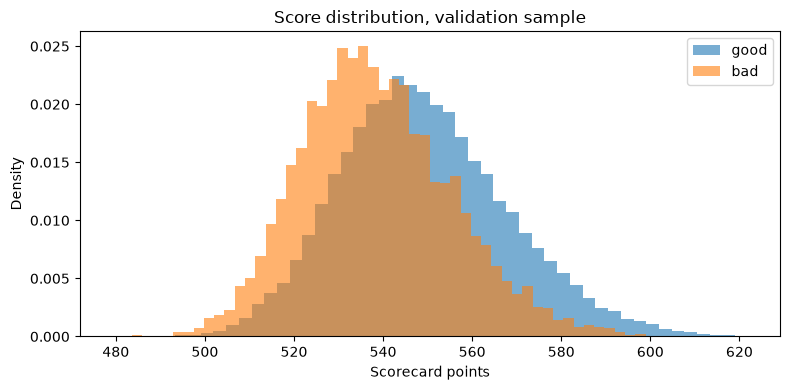

In [13]:
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
scores = pd.Series(card.score(valid), index=valid.index)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores[valid[TARGET] == 0], bins=50, alpha=0.6, density=True, label="good")
ax.hist(scores[valid[TARGET] == 1], bins=50, alpha=0.6, density=True, label="bad")
ax.set(xlabel="Scorecard points", ylabel="Density", title="Score distribution, validation sample")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "02_score_distribution_validation.png", dpi=150)

In [18]:
models_dir = config.ROOT / "models"
models_dir.mkdir(exist_ok=True)
with open(models_dir / "champion_scorecard.pkl", "wb") as f:
    pickle.dump(card, f)
points.drop(columns="bin_key").to_csv(config.REPORTS_DIR / "scorecard_points.csv", index=False)
selection_table.to_csv(config.REPORTS_DIR / "feature_selection.csv")

## 7. Findings

1. **Predictive power per feature is modest.** The strongest single feature is FICO (IV 0.126); only two features exceed IV 0.1. This is expected: every loan here was already *accepted* by Lending Club (FICO ≥ 660, internal policy rules), so the remaining applicants are more alike than a full applicant population.
2. **Past-delinquency and public-record fields carry almost no information here (IV ≈ 0).** A likely explanation is the same selection effect: applicants with recent serious delinquencies were mostly declined, and the few that remain fall below the 5% minimum bin size. This is an interpretation, not something the data can prove.
3. **Selection: 62 candidates → 13 features.** 36 dropped for IV < 0.02, 12 dropped because they duplicate a stronger feature (e.g. `tot_cur_bal` correlates 0.96 with `tot_hi_cred_lim`), 1 dropped for p-value > 0.01. Final VIFs are all below 2, so the coefficients are stable and interpretable.
4. **Every relationship has a sensible direction**: higher FICO, income and available card credit → lower risk; higher DTI, loan-to-income, recent account openings and recent credit enquiries → higher risk. All 13 coefficients are negative on WoE (as required) with p < 0.001.
5. **Missing values carry meaning.** "No credit enquiry on record" (11% of loans) is the *safest* `mths_since_recent_inq` group (9.4% bad, 49 points); "no installment account ever" is riskier than average (15.8% bad).
6. **Loan purpose**: wedding / vacation / medical / moving / small business / other is the riskiest group (17.6% bad, 30 points) vs car / major purchase / house / credit card (10.5% bad, 47 points).
7. **No material overfitting.** Gini 0.339 on train vs 0.326 on validation (KS 0.246 vs 0.237). Mean predicted PD on validation (12.43%) matches the observed bad rate (12.39%).
8. **Scorecard**: 600 points = 50:1 good:bad odds, +20 points doubles the odds; scores range roughly 480–620. Summing the rounded points reproduces the model score within 4 points.

**What to expect on Day 3:** OOT Gini will probably be somewhat lower, and since the 2014 bad rate (13.7%) is above the development rate (12.4%), the model should **underestimate** PD out of time — the calibration tests need to show whether that gap is statistically significant.